In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score
)

RANDOM_STATE = 42
N_SPLITS = 5
TARGET_COLUMN = "Machine failure"

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

print("Libraries imported successfully.")

Libraries imported successfully.


In [18]:
cwd = Path.cwd()

PROJECT_ROOT = next(
    (
        path
        for path in [cwd, *cwd.parents]
        if (path / "data" / "raw" / "ai4i2020.csv").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/raw/ai4i2020.csv. "
        "Check your notebook location and project folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"

df = pd.read_csv(DATA_PATH)

print("Project root:", PROJECT_ROOT)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Project root: d:\robotic-predictive-maintenance
Dataset shape: (10000, 14)
Columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1000,308.6000,1551,42.8000,0,0,0,0,0,0,0
1,2,L47181,L,298.2000,308.7000,1408,46.3000,3,0,0,0,0,0,0
2,3,L47182,L,298.1000,308.5000,1498,49.4000,5,0,0,0,0,0,0
3,4,L47183,L,298.2000,308.6000,1433,39.5000,7,0,0,0,0,0,0
4,5,L47184,L,298.2000,308.7000,1408,40.0000,9,0,0,0,0,0,0


In [19]:
NUMERICAL_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

CATEGORICAL_FEATURES = ["Type"]

FEATURE_COLUMNS = NUMERICAL_FEATURES + CATEGORICAL_FEATURES

EXCLUDED_COLUMNS = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

X = df[FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].astype(int).copy()

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nTarget proportions:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Input feature shape: (10000, 6)
Target shape: (10000,)

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Target proportions:
Machine failure
0   96.6100
1    3.3900
Name: proportion, dtype: float64


In [20]:
assert X.shape == (10000, 6), "Unexpected feature shape."
assert y.nunique() == 2, "Expected a binary target."
assert set(y.unique()) == {0, 1}, "Unexpected target labels."
assert TARGET_COLUMN not in X.columns
assert not set(EXCLUDED_COLUMNS).intersection(X.columns)

print("Feature and target validation passed.")
print("Failure rate:", round(y.mean() * 100, 2), "%")

Feature and target validation passed.
Failure rate: 3.39 %


In [21]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train_raw.shape)
print("Test features:", X_test_raw.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTest target distribution:")
print(y_test.value_counts().sort_index())

assert len(X_train_raw) == 8000
assert len(X_test_raw) == 2000
assert X_train_raw.index.intersection(X_test_raw.index).empty

print("\nTrain/test split validation passed.")

Training features: (8000, 6)
Test features: (2000, 6)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Test target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64

Train/test split validation passed.


In [22]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERICAL_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES)
])

print("Fold-specific preprocessing pipeline configured.")

Fold-specific preprocessing pipeline configured.


In [23]:
SCORING = {
    "average_precision": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc"
}

print("Evaluation metrics configured:")
for metric in SCORING:
    print("-", metric)

Evaluation metrics configured:
- average_precision
- recall
- precision
- f1
- balanced_accuracy
- roc_auc


In [24]:
models = {
    "Dummy_Baseline": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]),

    "Logistic_Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision_Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced",
            min_samples_leaf=5,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random_Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Extra_Trees": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", ExtraTreesClassifier(
            n_estimators=300,
            class_weight="balanced",
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Hist_Gradient_Boosting": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.1,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}

print("Models configured:")
for name, model in models.items():
    print(f"- {name}: {model.named_steps['classifier'].__class__.__name__}")

Models configured:
- Dummy_Baseline: DummyClassifier
- Logistic_Regression: LogisticRegression
- Decision_Tree: DecisionTreeClassifier
- Random_Forest: RandomForestClassifier
- Extra_Trees: ExtraTreesClassifier
- Hist_Gradient_Boosting: HistGradientBoostingClassifier


In [25]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Cross-validation:", N_SPLITS, "folds")

for fold, (_, val_idx) in enumerate(cv.split(X_train_raw, y_train), start=1):
    y_fold = y_train.iloc[val_idx]
    print(
        f"Fold {fold}: "
        f"{len(val_idx)} observations, "
        f"{int(y_fold.sum())} failures "
        f"({y_fold.mean() * 100:.2f}%)"
    )

Cross-validation: 5 folds
Fold 1: 1600 observations, 54 failures (3.38%)
Fold 2: 1600 observations, 54 failures (3.38%)
Fold 3: 1600 observations, 54 failures (3.38%)
Fold 4: 1600 observations, 54 failures (3.38%)
Fold 5: 1600 observations, 55 failures (3.44%)


In [26]:
cv_results = []

for name, model in models.items():
    print(f"Evaluating {name}...")

    scores = cross_validate(
        clone(model),
        X_train_raw,
        y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    row = {"model": name}

    for metric in SCORING:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)

    cv_results.append(row)

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "average_precision_mean",
    ascending=False
).reset_index(drop=True)

cv_results_df.round(4)

Evaluating Dummy_Baseline...


d:\robotic-predictive-maintenance\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\robotic-predictive-maintenance\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\robotic-predictive-maintenance\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\robo

Evaluating Logistic_Regression...
Evaluating Decision_Tree...
Evaluating Random_Forest...
Evaluating Extra_Trees...
Evaluating Hist_Gradient_Boosting...


,model,average_precision_mean,average_precision_std,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std
0,Hist_Gradient_Boosting,0.7846,0.0422,0.8043,0.0432,0.5846,0.0598,0.6763,0.0514,0.8920,0.0228,0.9714,0.0164
1,Random_Forest,0.7234,0.0358,0.8080,0.0342,0.5123,0.0179,0.6267,0.0164,0.8905,0.0165,0.9692,0.0158
2,Extra_Trees,0.6388,0.0320,0.7562,0.0454,0.3905,0.0459,0.5133,0.0410,0.8570,0.0214,0.9538,0.0112
3,Decision_Tree,0.6279,0.0612,0.7600,0.0660,0.5081,0.0415,0.6077,0.0403,0.8670,0.0326,0.8736,0.0334
4,Logistic_Regression,0.4409,0.0334,0.8044,0.0747,0.1374,0.0057,0.2346,0.0112,0.8138,0.0328,0.8965,0.0174
5,Dummy_Baseline,0.0339,0.0003,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.5000,0.0000


In [27]:
METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

results_path = METRICS_DIR / "baseline_cv_results.csv"

cv_results_df.to_csv(results_path, index=False)

print("Results saved to:", results_path)

Results saved to: d:\robotic-predictive-maintenance\artifacts\metrics\baseline_cv_results.csv


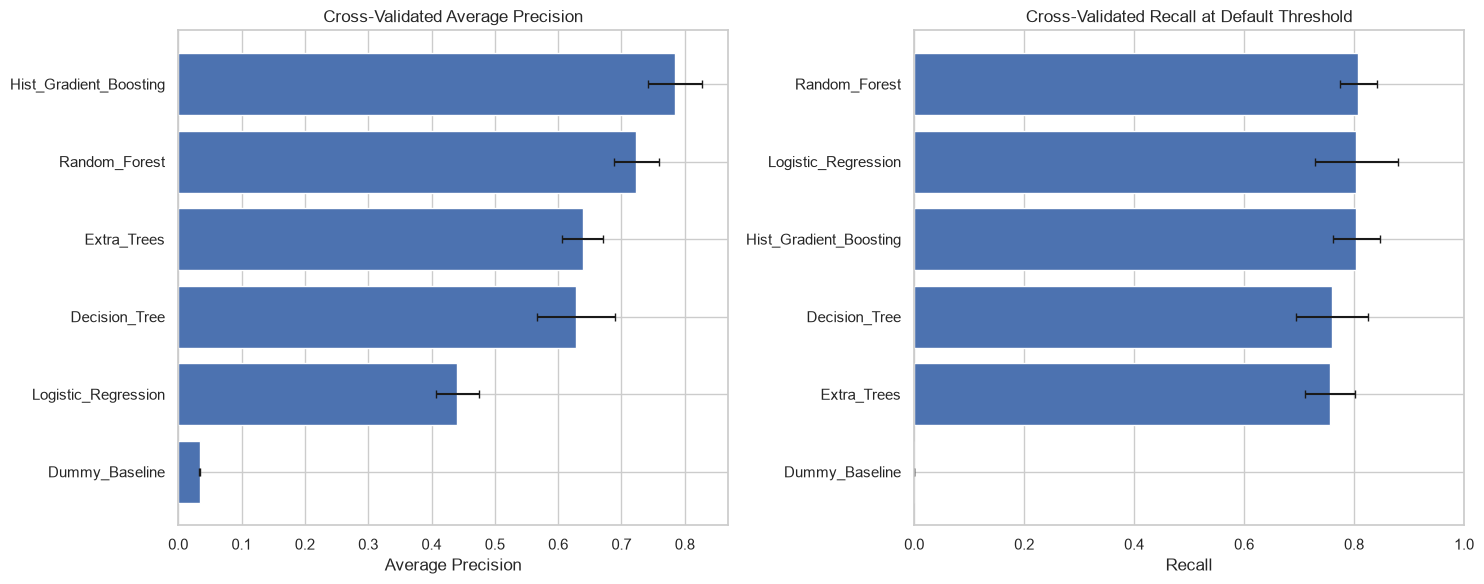

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

plot_df = cv_results_df.sort_values("average_precision_mean")

axes[0].barh(
    plot_df["model"],
    plot_df["average_precision_mean"],
    xerr=plot_df["average_precision_std"],
    capsize=3
)
axes[0].set_title("Cross-Validated Average Precision")
axes[0].set_xlabel("Average Precision")
axes[0].set_xlim(left=0)

plot_df = cv_results_df.sort_values("recall_mean")

axes[1].barh(
    plot_df["model"],
    plot_df["recall_mean"],
    xerr=plot_df["recall_std"],
    capsize=3
)
axes[1].set_title("Cross-Validated Recall at Default Threshold")
axes[1].set_xlabel("Recall")
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()